# Activité Pratique N°5 — Agentic AI et MCP
## Partie C : MCP (Model Context Protocol)

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

**Objectif** (reprise de la démo `mohamedYoussfi/mcp-demo`) :
1. Créer un **serveur MCP** qui expose **deux tools**
2. Le tester avec l'outil **`@modelcontextprotocol/inspector`**
3. Créer un **agent LangChain** et un **agent LangGraph** qui utilisent ce serveur via le protocole **streamable-http**
4. Créer un **agent N8N** qui utilise ce même serveur via **streamable-http**

```
                         ┌────────────────────────────────────────┐
 Agent LangChain ──┐     │  Serveur MCP  (mcp_demo/serveur_mcp.py)  │
 Agent LangGraph ──┼─ HTTP POST /mcp ─►  FastMCP, port 24000         │
 Agent N8N ────────┤  (JSON-RPC 2.0) │   • get_employee_infos(name)  │
 MCP Inspector ────┘     │   • search(query)  → Tavily              │
                         └────────────────────────────────────────┘
```
Le serveur ne contient **aucun LLM** : il publie des tools décrits par un schéma JSON. Chaque client découvre ces tools (`tools/list`) et les appelle (`tools/call`).

In [1]:
import json
import os
import shutil
import socket
import subprocess
import sys
import time
from pathlib import Path

from dotenv import load_dotenv
from IPython.display import Markdown, display

load_dotenv(override=True)
URL_MCP = "http://127.0.0.1:24000/mcp"

## 1. Le serveur MCP

Fichier `mcp_demo/serveur_mcp.py` : `FastMCP` transforme chaque fonction décorée par `@mcp.tool()` en tool MCP ; la **docstring** devient la description et les **annotations de type** le schéma des paramètres.

In [2]:
display(Markdown("```python\n" + Path("mcp_demo/serveur_mcp.py").read_text(encoding="utf-8") + "\n```"))

```python
"""Serveur MCP de la partie C : expose deux tools via le transport streamable-http.

Lancement, depuis le dossier de l'AP5 :
    uv run python mcp_demo/serveur_mcp.py
Point d'accès MCP : http://127.0.0.1:24000/mcp

Pour N8N lancé dans Docker, le serveur doit écouter sur toutes les interfaces :
    $env:MCP_HOST="0.0.0.0"; uv run python mcp_demo/serveur_mcp.py
puis utiliser l'URL http://host.docker.internal:24000/mcp dans N8N.
"""

import os
from pathlib import Path

from dotenv import load_dotenv
from langchain_tavily import TavilySearch
from mcp.server.fastmcp import FastMCP

load_dotenv(Path(__file__).resolve().parent.parent / ".env")

HOTE = os.getenv("MCP_HOST", "127.0.0.1")
PORT = int(os.getenv("MCP_PORT", "24000"))

mcp = FastMCP(name="mcp-server-ap5", host=HOTE, port=PORT)
recherche_web = TavilySearch(max_results=3)

EMPLOYES = {
    "hassan": {"nom": "Hassan", "poste": "Data Scientist", "salaire": 23000, "anciennete": 12},
    "salma": {"nom": "Salma", "poste": "Ingénieure MLOps", "salaire": 19500, "anciennete": 4},
    "yassine": {"nom": "Yassine", "poste": "Chef de projet IA", "salaire": 27000, "anciennete": 15},
}


@mcp.tool()
def get_employee_infos(name: str) -> dict:
    """Donne les informations RH d'un employé de l'entreprise : poste, salaire mensuel en MAD et ancienneté en années."""
    return EMPLOYES.get(name.strip().lower(), {"erreur": f"Aucun employé nommé {name}"})


@mcp.tool()
def search(query: str) -> dict:
    """Recherche des informations récentes sur le web (Tavily). Renvoie les 3 meilleurs résultats avec titre, URL et extrait."""
    resultats = recherche_web.invoke({"query": query})
    return {"query": query,
            "results": [{"title": r["title"], "url": r["url"], "content": r["content"][:500]}
                        for r in resultats.get("results", [])]}


if __name__ == "__main__":
    print(f"Serveur MCP sur http://{HOTE}:{PORT}/mcp", flush=True)
    mcp.run(transport="streamable-http")

```

### Démarrage du serveur

Dans un terminal : `uv run python mcp_demo/serveur_mcp.py`. Ici, il est lancé en arrière-plan depuis le notebook.
`MCP_HOST=0.0.0.0` permet aussi aux conteneurs Docker (Inspector, N8N) de le joindre via `host.docker.internal`.

In [3]:
def port_ouvert(port: int) -> bool:
    with socket.socket() as s:
        s.settimeout(1)
        return s.connect_ex(("127.0.0.1", port)) == 0


log_mcp = open("serveur_mcp.log", "w", encoding="utf-8")
serveur_mcp = subprocess.Popen(
    [sys.executable, "mcp_demo/serveur_mcp.py"],
    stdout=log_mcp, stderr=subprocess.STDOUT,
    env={**os.environ, "MCP_HOST": "0.0.0.0", "PYTHONIOENCODING": "utf-8"},
)
for _ in range(30):
    if port_ouvert(24000):
        break
    time.sleep(1)
print("Serveur MCP joignable :", port_ouvert(24000), "|", URL_MCP)

Serveur MCP joignable : True | http://127.0.0.1:24000/mcp


## 2. Ce qui circule sur le protocole : client MCP bas niveau

Le SDK `mcp` permet de voir les 3 étapes du protocole : `initialize`, `tools/list`, `tools/call`.

In [4]:
from mcp import ClientSession
from mcp.client.streamable_http import streamablehttp_client

async with streamablehttp_client(URL_MCP) as (lecture, ecriture, _):
    async with ClientSession(lecture, ecriture) as session:
        init = await session.initialize()
        print(f"Serveur : {init.serverInfo.name} v{init.serverInfo.version} | protocole {init.protocolVersion}\n")

        liste = await session.list_tools()
        for outil in liste.tools:
            print(f"tool « {outil.name} » : {outil.description}")
            print(f"   schéma : {json.dumps(outil.inputSchema['properties'], ensure_ascii=False)}")

        resultat = await session.call_tool("get_employee_infos", {"name": "Hassan"})
        print("\ntools/call get_employee_infos(Hassan) ->", resultat.content[0].text.replace("\n", " "))

Serveur : mcp-server-ap5 v1.30.0 | protocole 2025-11-25

tool « get_employee_infos » : Donne les informations RH d'un employé de l'entreprise : poste, salaire mensuel en MAD et ancienneté en années.
   schéma : {"name": {"title": "Name", "type": "string"}}
tool « search » : Recherche des informations récentes sur le web (Tavily). Renvoie les 3 meilleurs résultats avec titre, URL et extrait.
   schéma : {"query": {"title": "Query", "type": "string"}}

tools/call get_employee_infos(Hassan) -> {   "nom": "Hassan",   "poste": "Data Scientist",   "salaire": 23000,   "anciennete": 12 }


## 3. Test avec MCP Inspector

**Interface web** (dans un terminal) :
```bash
npx @modelcontextprotocol/inspector
```
puis dans le navigateur (`http://localhost:6274`) : *Transport Type* = **Streamable HTTP**, *URL* = `http://127.0.0.1:24000/mcp`, **Connect** → onglet **Tools** → **List Tools** → choisir un tool, remplir les paramètres, **Run Tool**.

Sur ce PC, le registre npm est bloqué par le réseau : l'Inspector est donc lancé avec son **image Docker officielle** (`ghcr.io/modelcontextprotocol/inspector`), identique au paquet npm. Interface web via Docker :
```bash
docker run --rm -p 6274:6274 -p 6277:6277 -e HOST=0.0.0.0 ghcr.io/modelcontextprotocol/inspector
```
(URL du serveur à saisir depuis le conteneur : `http://host.docker.internal:24000/mcp`).

Ci-dessous, le **mode CLI** de l'Inspector, qui exécute les mêmes requêtes que l'interface web.

In [5]:
IMAGE_INSPECTOR = "ghcr.io/modelcontextprotocol/inspector:latest"
URL_DEPUIS_DOCKER = "http://host.docker.internal:24000/mcp"


def inspector(*arguments: str) -> str:
    if shutil.which("npx") and os.getenv("INSPECTOR_NPX") == "1":
        commande = ["npx", "-y", "@modelcontextprotocol/inspector", "--cli", URL_MCP]
    else:
        commande = ["docker", "run", "--rm", IMAGE_INSPECTOR, "--cli", URL_DEPUIS_DOCKER]
    resultat = subprocess.run(commande + ["--transport", "http", *arguments],
                              capture_output=True, text=True, encoding="utf-8", timeout=180)
    return resultat.stdout or resultat.stderr


reponse = json.loads(inspector("--method", "tools/list"))
for outil in reponse["tools"]:
    print(f"- {outil['name']} : paramètres {outil['inputSchema']['required']}")

- get_employee_infos : paramètres ['name']
- search : paramètres ['query']


In [6]:
print(inspector("--method", "tools/call", "--tool-name", "get_employee_infos", "--tool-arg", "name=Salma"))

{
  "content": [
    {
      "type": "text",
      "text": "{\n  \"nom\": \"Salma\",\n  \"poste\": \"Ingénieure MLOps\",\n  \"salaire\": 19500,\n  \"anciennete\": 4\n}"
    }
  ],
  "isError": false
}



In [7]:
reponse = json.loads(inspector("--method", "tools/call", "--tool-name", "search", "--tool-arg", "query=Model Context Protocol"))
resultats = json.loads(reponse["content"][0]["text"])["results"]
for r in resultats:
    print(f"- {r['title']} | {r['url']}")

- Model Context Protocol | https://en.wikipedia.org/wiki/Model_Context_Protocol
- What is Model Context Protocol (MCP)? A guide | Google Cloud | https://cloud.google.com/discover/what-is-model-context-protocol
- Model Context Protocol (MCP): A comprehensive introduction for developers | https://stytch.com/blog/model-context-protocol-introduction


## 4. Agent LangChain client du serveur MCP

`MultiServerMCPClient` (paquet `langchain-mcp-adapters`) se connecte au serveur, récupère les tools et les convertit en tools LangChain. L'agent ne contient aucun code métier : il ne connaît que les **descriptions** publiées par le serveur.

In [8]:
from langchain.agents import create_agent
from langchain.messages import AIMessage, HumanMessage
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_openai import AzureChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver

client_mcp = MultiServerMCPClient({
    "mcp_server": {"transport": "streamable_http", "url": URL_MCP},
})
outils_mcp = await client_mcp.get_tools()
print("Tools récupérés :", [o.name for o in outils_mcp])

llm = AzureChatOpenAI(
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    api_version=os.getenv("AZURE_OPENAI_API_VERSION"),
    azure_deployment=os.getenv("AZURE_OPENAI_DEPLOYMENT"),
    temperature=0,
    timeout=60,
)

agent_langchain = create_agent(
    model=llm,
    tools=outils_mcp,
    system_prompt="Réponds en français en utilisant les tools fournis. N'invente aucune donnée et cite les URL des sources web.",
    checkpointer=InMemorySaver(),
)

Tools récupérés : ['get_employee_infos', 'search']


In [9]:
async def demander(agent, question: str, thread_id: str = "1"):
    reponse = await agent.ainvoke({"messages": [HumanMessage(question)]}, config={"configurable": {"thread_id": thread_id}})
    dernier_humain = max(i for i, m in enumerate(reponse["messages"]) if isinstance(m, HumanMessage))
    appels = [f"{tc['name']}({tc['args']})" for m in reponse["messages"][dernier_humain:]
              if isinstance(m, AIMessage) for tc in m.tool_calls]
    print(f"Question : {question}\nTools MCP appelés : {appels}")
    display(Markdown(reponse["messages"][-1].content))
    print("-" * 80)


await demander(agent_langchain, "Quel est le salaire de Hassan ?")
await demander(agent_langchain, "Compare son ancienneté avec celle de Yassine.")
await demander(agent_langchain, "Quelles sont les dernières nouveautés du protocole MCP ? Donne 2 points avec leurs sources.")

Question : Quel est le salaire de Hassan ?
Tools MCP appelés : ["get_employee_infos({'name': 'Hassan'})"]


Le salaire mensuel de Hassan est de 23 000 MAD.

--------------------------------------------------------------------------------


Question : Compare son ancienneté avec celle de Yassine.
Tools MCP appelés : ["get_employee_infos({'name': 'Hassan'})", "get_employee_infos({'name': 'Yassine'})"]


Hassan a une ancienneté de 12 ans, tandis que Yassine a une ancienneté de 15 ans. Yassine a donc 3 ans d'ancienneté de plus que Hassan.

--------------------------------------------------------------------------------


Question : Quelles sont les dernières nouveautés du protocole MCP ? Donne 2 points avec leurs sources.
Tools MCP appelés : ["search({'query': 'dernières nouveautés protocole MCP'})"]


Voici deux points récents concernant le protocole MCP :

1. La spécification MCP 2026-07-28 a été publiée récemment, avec des SDK mis à jour en TypeScript, Python, Go et C#. MCP est désormais un protocole entièrement sans état, ce qui permet aux serveurs MCP de fonctionner uniquement dans un Worker, sans infrastructure avec état, simplifiant ainsi l'exploitation et réduisant les coûts. Source : https://blog.cloudflare.com/mcp-v2

2. Le protocole MCP définit l'autorisation en utilisant un autre protocole, OAuth. Cependant, la communauté a identifié que la spécification actuelle inclut des détails de mise en œuvre qui posent certains risques de sécurité, ce qui est un point important à considérer. Source : https://www.redhat.com/fr/blog/model-context-protocol-mcp-understanding-security-risks-and-controls

--------------------------------------------------------------------------------


## 5. Agent LangGraph client du serveur MCP

Les mêmes tools MCP, utilisés dans un graphe LangGraph construit à la main (nœud LLM + `ToolNode` + boucle). Les tools MCP sont asynchrones : le graphe est appelé avec `ainvoke`.

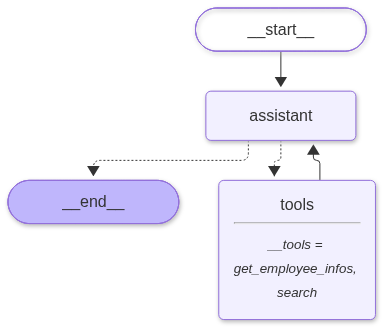

In [10]:
from typing import Literal

from langchain.messages import SystemMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode

llm_avec_outils = llm.bind_tools(outils_mcp)


async def assistant(etat: MessagesState) -> dict:
    systeme = SystemMessage("Tu es un assistant RH et veille technologique. Réponds en français avec les tools fournis.")
    return {"messages": [await llm_avec_outils.ainvoke([systeme] + etat["messages"])]}


def continuer(etat: MessagesState) -> Literal["tools", "__end__"]:
    return "tools" if etat["messages"][-1].tool_calls else END


graphe = StateGraph(MessagesState)
graphe.add_node("assistant", assistant)
graphe.add_node("tools", ToolNode(outils_mcp))
graphe.add_edge(START, "assistant")
graphe.add_conditional_edges("assistant", continuer)
graphe.add_edge("tools", "assistant")
agent_langgraph = graphe.compile(checkpointer=InMemorySaver())

try:
    from IPython.display import Image
    display(Image(agent_langgraph.get_graph().draw_mermaid_png()))
except Exception:
    print(agent_langgraph.get_graph().draw_mermaid())

In [11]:
await demander(agent_langgraph, "Donne le poste de Salma et cherche sur le web une définition du métier de MLOps (avec la source).", thread_id="lg-1")

Question : Donne le poste de Salma et cherche sur le web une définition du métier de MLOps (avec la source).
Tools MCP appelés : ["get_employee_infos({'name': 'Salma'})", "search({'query': 'définition métier MLOps'})"]


Salma occupe le poste d'Ingénieure MLOps.

Voici une définition du métier de MLOps issue du site Databricks : 
"MLOps signifie Machine Learning Operations, ou opérations de machine learning. Fonction fondamentale de l'ingénierie du machine learning, les MLOps ont pour mission de normaliser le processus de mise en production des modèles de machine learning puis d'en assurer la maintenance et la supervision. Les MLOps sont une fonction collaborative qui réunit généralement des data scientists, des ingénieurs DevOps et l'IT."
Source : https://www.databricks.com/fr/blog/what-is-mlops

Souhaitez-vous plus d'informations sur ce métier ?

--------------------------------------------------------------------------------


## 6. Agent N8N client du serveur MCP

Workflow fourni : `mcp_demo/n8n_agent_mcp.json`

```
 Chat Trigger ──► AI Agent ──┬── Chat Model : Microsoft Foundry / Azure OpenAI (gpt-4.1-mini)
                             ├── Memory : Simple Memory (10 messages)
                             └── Tool : MCP Client Tool  →  http://host.docker.internal:24000/mcp
                                         Server Transport = HTTP Streamable
```

**Mise en place :**
1. Lancer le serveur MCP en écoute sur toutes les interfaces :
   ```powershell
   $env:MCP_HOST="0.0.0.0"; uv run python mcp_demo/serveur_mcp.py
   ```
2. Lancer N8N :
   ```bash
   docker run -it --rm -p 5678:5678 --add-host=host.docker.internal:host-gateway -v n8n_data:/home/node/.n8n n8nio/n8n
   ```
   (ou `npx n8n`, dans ce cas l'URL MCP est `http://127.0.0.1:24000/mcp`)
3. Ouvrir `http://localhost:5678`, créer le compte local, puis **Workflows → Import from File** → `mcp_demo/n8n_agent_mcp.json`
4. Nœud **Azure OpenAI** → *Credential* → **Microsoft Foundry (API Key)** : *Endpoint Type* = Classic, *API Key*, *Resource Name* (le sous-domaine de `AZURE_OPENAI_ENDPOINT`), *API Version* ; *Model (Deployment) Name* = `gpt-4.1-mini`
5. Nœud **MCP Client Tool** : vérifier l'*Endpoint* et *Server Transport* = **HTTP Streamable**
6. **Open chat** pour tester, ou **Publish** pour activer l'URL de production `POST /webhook/ap5-agent-mcp/chat`

La cellule suivante interroge le workflow N8N publié, s'il tourne sur `localhost:5678`.

In [12]:
import httpx

URL_CHAT_N8N = "http://localhost:5678/webhook/ap5-agent-mcp/chat"


def demander_n8n(question: str, session: str = "notebook-ap5") -> str:
    reponse = httpx.post(URL_CHAT_N8N, json={"action": "sendMessage", "sessionId": session, "chatInput": question}, timeout=180)
    reponse.raise_for_status()
    return reponse.json()["output"]


if port_ouvert(5678):
    for question in ["Quel est le poste et le salaire de Salma ?",
                     "Et qui a le plus d'ancienneté entre elle et Yassine ?",
                     "Cherche sur le web ce qu'est N8N, en une phrase avec la source."]:
        print(f"Question : {question}\nAgent N8N : {demander_n8n(question)}\n")
else:
    print("N8N n'est pas lancé sur le port 5678 : voir les étapes ci-dessus.")

Question : Quel est le poste et le salaire de Salma ?
Agent N8N : Salma occupe le poste d'Ingénieure MLOps et son salaire mensuel est de 19 500 MAD. Souhaitez-vous d'autres informations ?



Question : Et qui a le plus d'ancienneté entre elle et Yassine ?
Agent N8N : Yassine a plus d'ancienneté que Salma. Yassine a 15 ans d'ancienneté tandis que Salma en a 4. Souhaitez-vous d'autres informations ?



Question : Cherche sur le web ce qu'est N8N, en une phrase avec la source.
Agent N8N : N8N est une plateforme d'automatisation des flux de travail qui permet de créer des automatisations en reliant des applications, services et modèles d'IA via un éditeur visuel basé sur des nœuds, avec la possibilité d'utiliser du JavaScript ou Python personnalisé (source : https://en.wikipedia.org/wiki/N8n).



## 7. Arrêt du serveur MCP

In [13]:
import psutil

# Sous Windows, le python.exe d'un environnement uv lance l'interpréteur réel en processus enfant : on arrête les deux
processus = psutil.Process(serveur_mcp.pid)
for p in processus.children(recursive=True) + [processus]:
    p.kill()
time.sleep(1)
log_mcp.close()
print("Serveur MCP arrêté | port 24000 ouvert :", port_ouvert(24000))

Serveur MCP arrêté | port 24000 ouvert : False


**Bilan :** un seul serveur MCP, quatre clients différents (Inspector, agent LangChain, agent LangGraph, agent N8N) sans aucune modification du serveur. C'est l'intérêt du protocole : les tools sont **publiés une fois** et **réutilisables** par n'importe quel client MCP, quel que soit le framework ou le LLM.